# 01 - Gaussian Blur Visualization

## Objective

Build intuition for the Gaussian blur that will be applied to raw pixels before logistic regression.

Steps:

1. Blur examples of every digit at increasing $\sigma$.
2. The average image of each digit for a fixed $\sigma$

All pixel intensities are scaled to [0, 1]. $\sigma$ is measured in pixels.

## Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mnist_rbf import GaussianBlur, load_mnist, save_figure

## Dataset Acquisition

In [2]:
X, y = load_mnist(scale=True, dtype=np.float32)

print("X:", X.shape, X.dtype, f"range [{X.min():.1f}, {X.max():.1f}]")
print("y:", y.shape, y.dtype)

SIGMAS = [0, 0.5, 1, 1.5, 2, 3]

# Blur the whole dataset once per sigma (the blur is stateless, so no leakage concern)
X_blur = {s: GaussianBlur(sigma=s).fit_transform(X) for s in SIGMAS}

# First example of each digit
digits, first_idx = np.unique(y, return_index=True)

Loading MNIST from local storage.
X: (70000, 784) float32 range [0.0, 1.0]
y: (70000,) uint8


## Blur Across Sigma

### One digit, increasing sigma

Small $\sigma$ (0.5 to 1) only softens stroke edges. Around $\sigma = 2$ to $3$ the stroke width is comparable to the kernel, and thin features such as the gap in a 4 or the loop of a 6 start to merge.

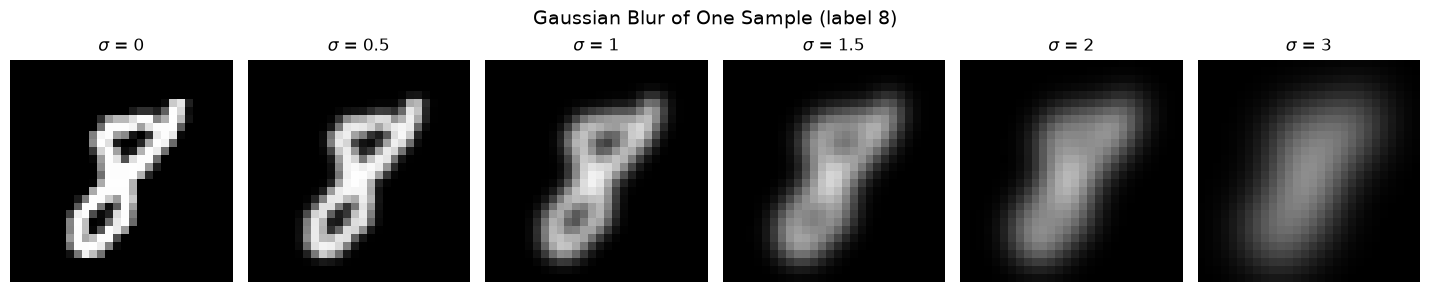

In [3]:
example_idx = first_idx[8] 

fig, axes = plt.subplots(1, len(SIGMAS), figsize=(2.4 * len(SIGMAS), 3))

for ax, s in zip(axes, SIGMAS):
    ax.imshow(X_blur[s][example_idx].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(r"$\sigma$ = " + f"{s}")
    ax.axis("off")

plt.suptitle(f"Gaussian Blur of One Sample (label {y[example_idx]})", fontsize=14)
plt.tight_layout()

save_figure(fig, "blur-single-sample.png")

plt.show()

### Every digit, every sigma

Rows are digits and columns are $\sigma$. All panels share the same intensity scale ($[0, 1]$), so the dimming of thin strokes at large $\sigma$ is visible.

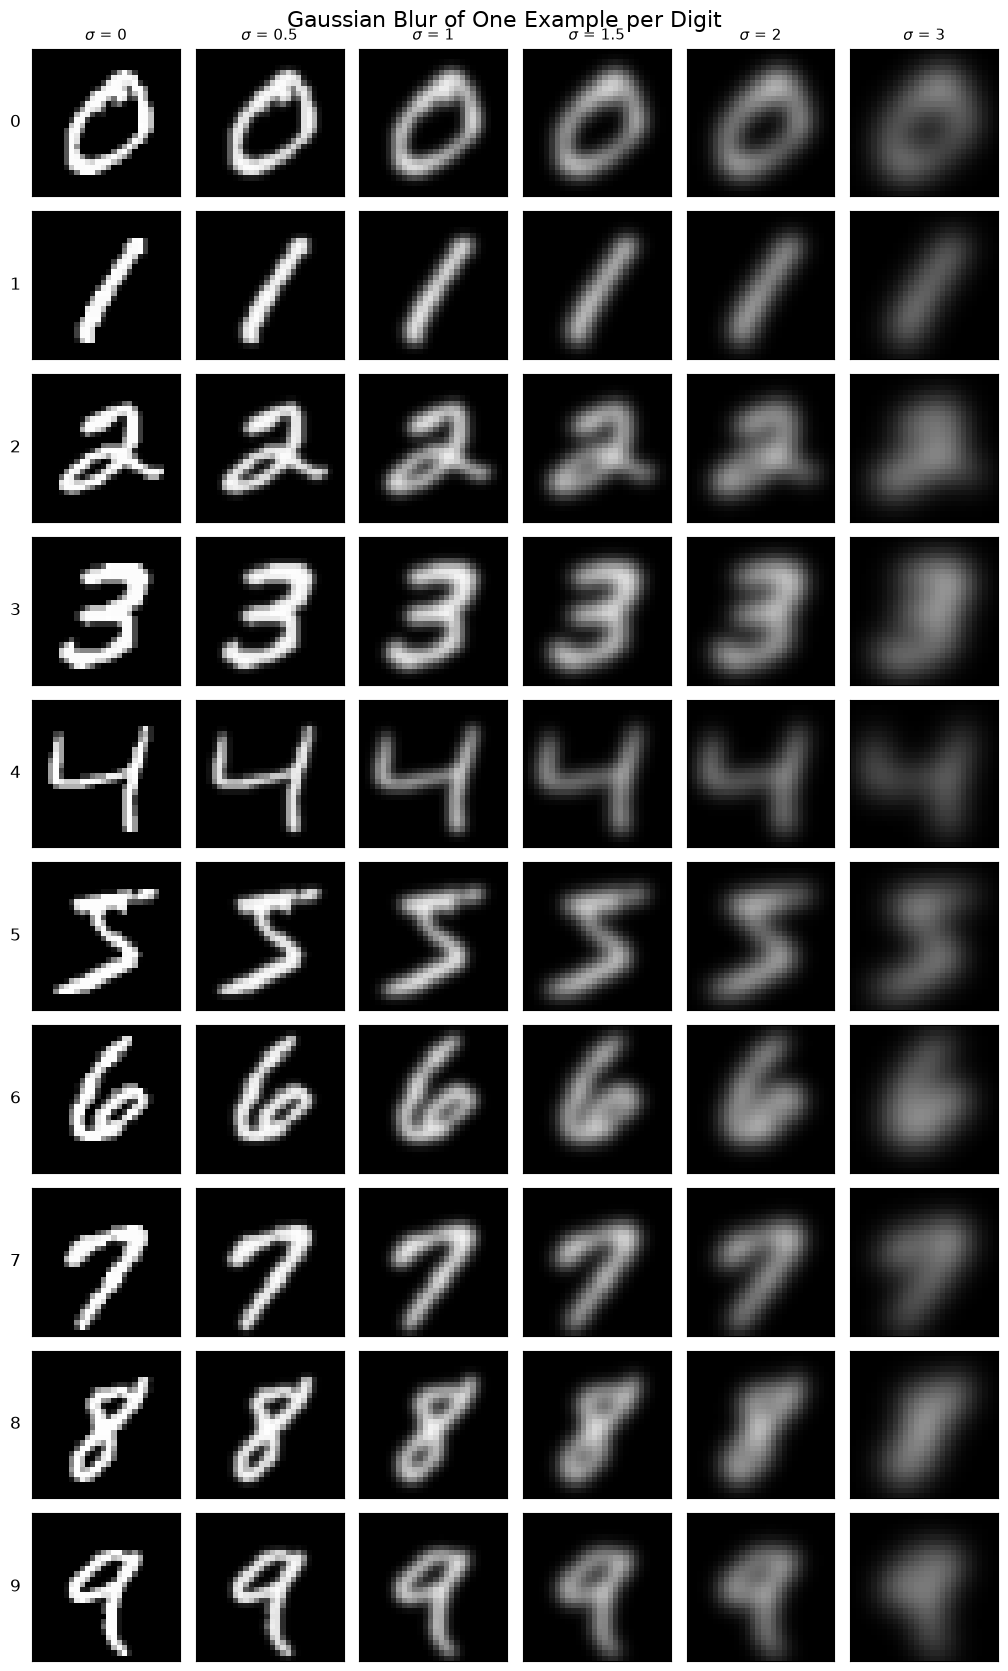

In [8]:
fig, axes = plt.subplots(
    len(digits),
    len(SIGMAS),
    figsize=(1.7 * len(SIGMAS), 1.7 * len(digits)),
)

for row, (digit, idx) in enumerate(zip(digits, first_idx)):
    for col, s in enumerate(SIGMAS):
        ax = axes[row, col]
        ax.imshow(X_blur[s][idx].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(r"$\sigma$ = " + f"{s}", fontsize=11)
        if col == 0:
            ax.set_ylabel(f"{digit}", rotation=0, labelpad=12, fontsize=12, va="center")

plt.suptitle("Gaussian Blur of One Example per Digit", fontsize=16)
plt.tight_layout()

save_figure(fig, "blur-all-digits-grid.png")

plt.show()

## Average image per digit for fixed $\sigma$

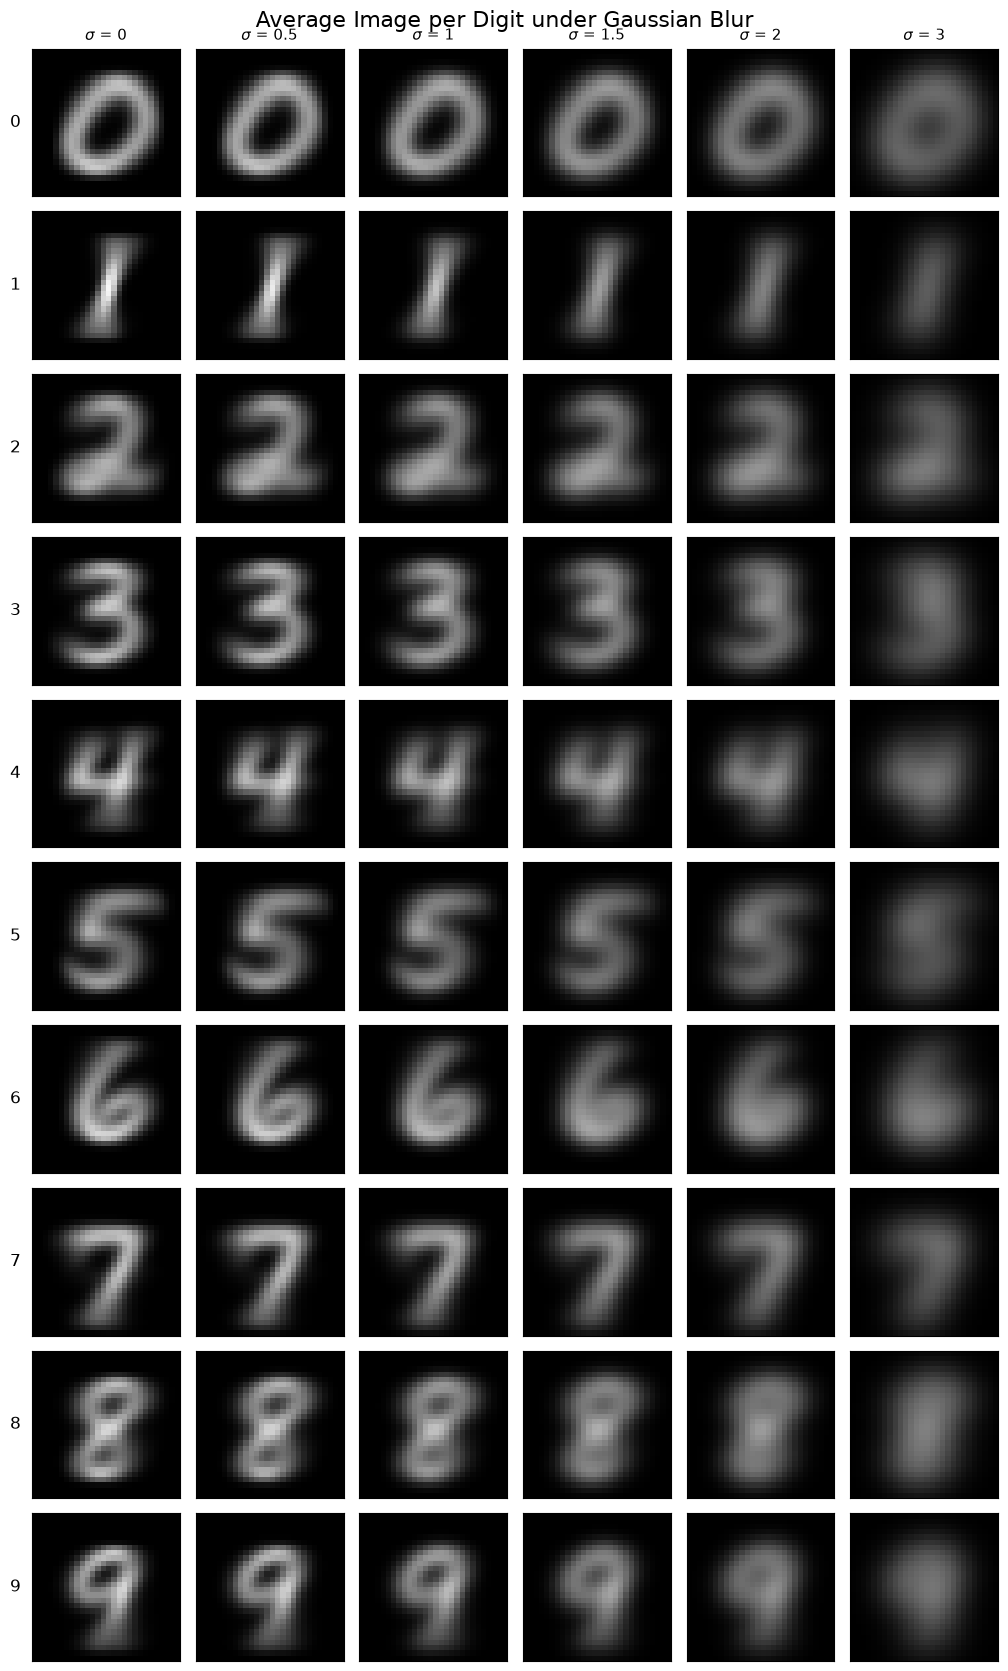

In [11]:
fig, axes = plt.subplots(
    len(digits),
    len(SIGMAS),
    figsize=(1.7 * len(SIGMAS), 1.7 * len(digits)),
)

for row, digit in enumerate(digits):
    mask = (y == digit)
    for col, s in enumerate(SIGMAS):
        ax = axes[row, col]
        mean_img = X_blur[s][mask].mean(axis=0)
        ax.imshow(mean_img.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(r"$\sigma$ = " + f"{s}", fontsize=11)
        if col == 0:
            ax.set_ylabel(f"{digit}", rotation=0, labelpad=12, fontsize=12, va="center")

plt.suptitle("Average Image per Digit under Gaussian Blur", fontsize=16)
plt.tight_layout()

save_figure(fig, "blur-all-digits-mean-grid.png")

plt.show()